# ĐỀ TÀI: HỆ THỐNG HỖ TRỢ RA QUYẾT ĐỊNH (DSS) CẢNH BÁO CHẤT LƯỢNG KHÔNG KHÍ & KHUYẾN NGHỊ HOẠT ĐỘNG NGOÀI TRỜI

**Môn học:** Hệ thống Hỗ trợ Ra Quyết định (Decision Support Systems - DSS)  
**Khu vực nghiên cứu:** Hà Nội & TP. Hồ Chí Minh  
**Nguồn dữ liệu:** Open-Meteo Air Quality API & Open-Meteo Weather Forecast API  

---

### Mục tiêu đồ án:
1. **Thu thập & tiền xử lý dữ liệu:** Lấy dữ liệu quan trắc chuỗi thời gian (AQI, PM2.5, PM10, Nhiệt độ, Độ ẩm, Mưa, UV, Gió) cho 2 đô thị lớn tại Việt Nam.
2. **Phân tích khám phá dữ liệu (EDA):** Tìm hiểu quy luật ô nhiễm không khí theo khung giờ trong ngày, tương quan giữa các yếu tố khí tượng và nồng độ bụi mịn PM2.5.
3. **Mô hình hóa Cơ sở Tri thức & Động cơ Luật DSS (Rule-Based Inference Engine):**
   - Đưa ra quyết định: Có nên chạy bộ / tập thể dục ngoài trời không?
   - Đưa ra quyết định: Có cần đeo khẩu trang không? (Loại thông thường hay N95)?
   - Đưa ra quyết định: Có cho trẻ em, người cao tuổi ra ngoài không?
4. **Kiểm thử kịch bản (Scenario Testing):** Đánh giá tính hợp lý và nhất quán của hệ thống trên các kịch bản thực tế.

In [1]:
# 1. KHAI BÁO CÁC THƯ VIỆN CẦN THIẾT
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị đồ thị thẩm mỹ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Thêm đường dẫn src để tái sử dụng module
sys.path.append(os.path.abspath('..'))
from src.rule_engine import evaluate_dss, get_aqi_info, generate_decision_rules_df

print("✓ Đã nạp thành công các thư viện phân tích!")

✓ Đã nạp thành công các thư viện phân tích!


## 2. NẠP DỮ LIỆU & KIỂM TRA CẤU TRÚC (DATA LOADING & INSPECTION)

Dữ liệu được đọc trực tiếp từ các file dataset CSV đã thu thập từ API và tiền xử lý trong thư mục `../data/` (hoặc `data/`).

In [2]:
# Kiểm tra đường dẫn thư mục data
data_dir = '../data' if os.path.exists('../data') else 'data'

hanoi_path = os.path.join(data_dir, 'air_quality_hanoi.csv')
hcm_path = os.path.join(data_dir, 'air_quality_hcm.csv')
rules_path = os.path.join(data_dir, 'dss_decision_rules.csv')

df_hanoi = pd.read_csv(hanoi_path)
df_hcm = pd.read_csv(hcm_path)
df_rules = pd.read_csv(rules_path)

# Chuyển đổi timestamp sang định dạng datetime
df_hanoi['timestamp'] = pd.to_datetime(df_hanoi['timestamp'])
df_hcm['timestamp'] = pd.to_datetime(df_hcm['timestamp'])

print(f"Hà Nội: {len(df_hanoi)} bản ghi | Khoảng thời gian: {df_hanoi['timestamp'].min()} đến {df_hanoi['timestamp'].max()}")
print(f"TP.HCM: {len(df_hcm)} bản ghi | Khoảng thời gian: {df_hcm['timestamp'].min()} đến {df_hcm['timestamp'].max()}")
print(f"Bảng luật DSS: {len(df_rules)} quy tắc cơ sở")

# Hiển thị 5 dòng đầu của Hà Nội
df_hanoi[['timestamp', 'aqi_us', 'pm2_5', 'pm10', 'temperature_2m', 'relative_humidity_2m', 'aqi_category']].head()

Hà Nội: 792 bản ghi | Khoảng thời gian: 2026-09-12 00:00:00 đến 2026-10-14 23:00:00
TP.HCM: 792 bản ghi | Khoảng thời gian: 2026-09-12 00:00:00 đến 2026-10-14 23:00:00
Bảng luật DSS: 9 quy tắc cơ sở


,timestamp,aqi_us,pm2_5,pm10,temperature_2m,relative_humidity_2m,aqi_category
0,2026-09-12 00:00:00,98,43.7,45.1,24.0,74,Trung bình
1,2026-09-12 01:00:00,98,44.8,46.1,24.4,72,Trung bình
2,2026-09-12 02:00:00,98,45.3,46.7,24.2,70,Trung bình
3,2026-09-12 03:00:00,98,46.0,47.4,24.0,70,Trung bình
4,2026-09-12 04:00:00,99,44.1,45.5,23.8,69,Trung bình


## 3. THỐNG KÊ MÔ TẢ & TIỀN XỬ LÝ ĐẶC TRƯNG

Trích xuất các đặc trưng thời gian (giờ trong ngày, ngày trong tuần) để phân tích chu kỳ sinh hoạt đô thị.

In [3]:
for df in [df_hanoi, df_hcm]:
    df['hour'] = df['timestamp'].dt.hour
    df['day_name'] = df['timestamp'].dt.day_name()

# So sánh các chỉ số thống kê trung bình giữa Hà Nội và TP.HCM
comparison_metrics = ['aqi_us', 'pm2_5', 'pm10', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m']
stats_df = pd.DataFrame({
    'Hà Nội (Trung bình)': df_hanoi[comparison_metrics].mean(),
    'Hà Nội (Max)': df_hanoi[comparison_metrics].max(),
    'TP.HCM (Trung bình)': df_hcm[comparison_metrics].mean(),
    'TP.HCM (Max)': df_hcm[comparison_metrics].max()
})
stats_df.round(2)

,Hà Nội (Trung bình),Hà Nội (Max),TP.HCM (Trung bình),TP.HCM (Max)
aqi_us,129.35,220.0,92.02,172.0
pm2_5,52.28,192.8,30.14,94.3
pm10,53.76,195.6,31.42,95.9
temperature_2m,27.22,34.6,27.22,33.4
relative_humidity_2m,78.78,100.0,86.82,100.0
wind_speed_10m,7.68,20.7,5.55,15.8


## 4. PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS - EDA)

### 4.1. Biến thiên nồng độ PM2.5 theo 24 giờ trong ngày
Xác định khung giờ ô nhiễm cao điểm (sáng sớm và chiều tối) và khung giờ không khí trong lành nhất trong ngày.

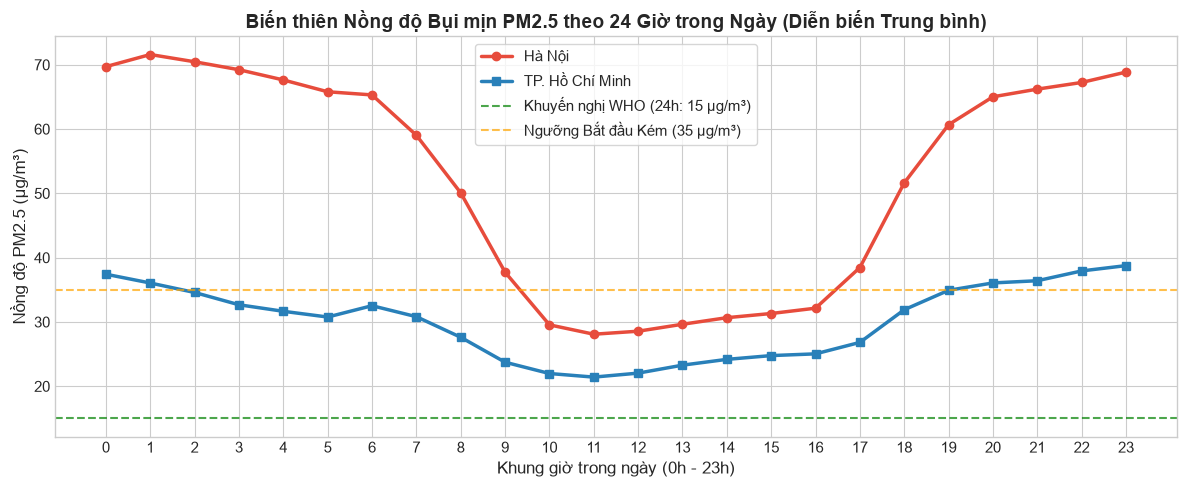

In [4]:
hourly_hanoi = df_hanoi.groupby('hour')['pm2_5'].mean()
hourly_hcm = df_hcm.groupby('hour')['pm2_5'].mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly_hanoi.index, hourly_hanoi.values, marker='o', linewidth=2.5, color='#e74c3c', label='Hà Nội')
plt.plot(hourly_hcm.index, hourly_hcm.values, marker='s', linewidth=2.5, color='#2980b9', label='TP. Hồ Chí Minh')

plt.axhline(y=15, color='green', linestyle='--', alpha=0.7, label='Khuyến nghị WHO (24h: 15 µg/m³)')
plt.axhline(y=35, color='orange', linestyle='--', alpha=0.7, label='Ngưỡng Bắt đầu Kém (35 µg/m³)')

plt.title('Biến thiên Nồng độ Bụi mịn PM2.5 theo 24 Giờ trong Ngày (Diễn biến Trung bình)', fontsize=14, fontweight='bold')
plt.xlabel('Khung giờ trong ngày (0h - 23h)', fontsize=12)
plt.ylabel('Nồng độ PM2.5 (µg/m³)', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### 4.2. Ma trận tương quan giữa Ô nhiễm và Khí tượng
Khám phá mối liên hệ giữa nồng độ bụi $PM_{2.5}$ với Độ ẩm, Nhiệt độ, Vận tốc gió và Mưa.

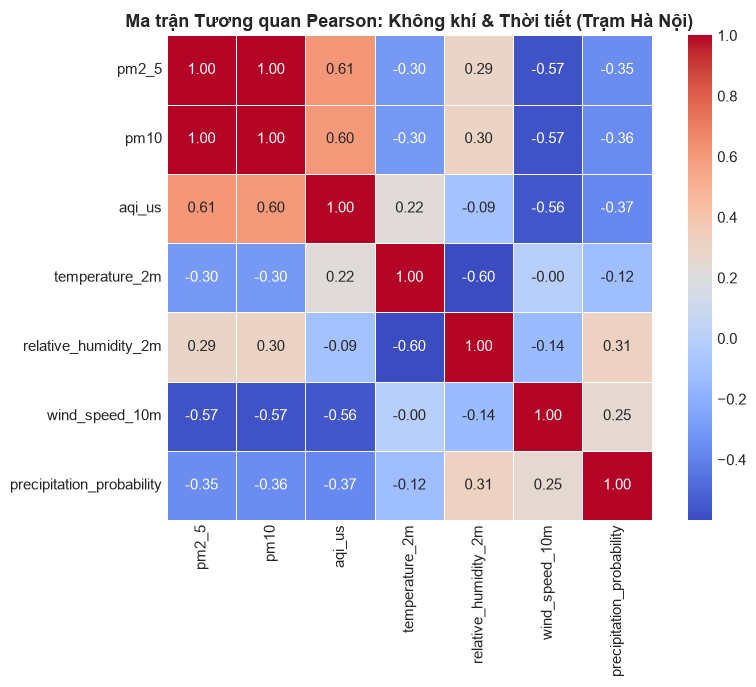

In [5]:
corr_cols = ['pm2_5', 'pm10', 'aqi_us', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'precipitation_probability']
corr_matrix = df_hanoi[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
plt.title('Ma trận Tương quan Pearson: Không khí & Thời tiết (Trạm Hà Nội)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.3. Phân bố các mức độ chất lượng không khí (AQI Categories)

C:\Users\MD15\AppData\Local\Temp\ipykernel_17872\3419063219.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hanoi_counts[present_order_hn].index, y=hanoi_counts[present_order_hn].values, ax=axes[0], palette=palette)
C:\Users\MD15\AppData\Local\Temp\ipykernel_17872\3419063219.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hcm_counts[present_order_hcm].index, y=hcm_counts[present_order_hcm].values, ax=axes[1], palette=palette)


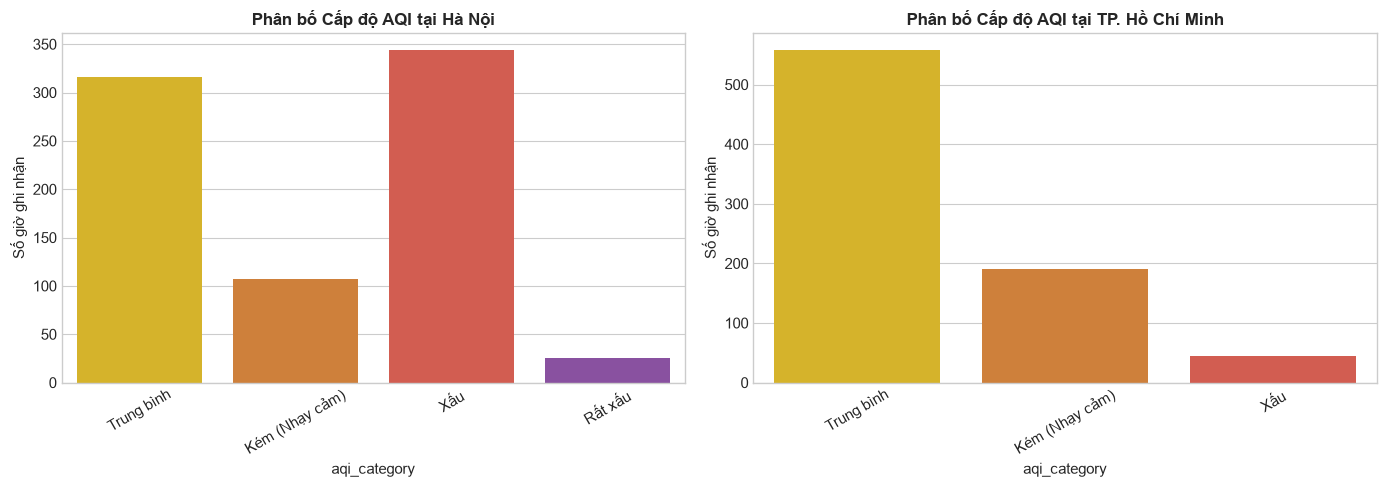

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = ['Tốt', 'Trung bình', 'Kém (Nhạy cảm)', 'Xấu', 'Rất xấu', 'Nguy hại']
palette = {'Tốt': '#2ecc71', 'Trung bình': '#f1c40f', 'Kém (Nhạy cảm)': '#e67e22', 'Xấu': '#e74c3c', 'Rất xấu': '#8e44ad', 'Nguy hại': '#7e0023'}

# Đếm tần suất
hanoi_counts = df_hanoi['aqi_category'].value_counts()
hcm_counts = df_hcm['aqi_category'].value_counts()

present_order_hn = [cat for cat in order if cat in hanoi_counts]
present_order_hcm = [cat for cat in order if cat in hcm_counts]

sns.barplot(x=hanoi_counts[present_order_hn].index, y=hanoi_counts[present_order_hn].values, ax=axes[0], palette=palette)
axes[0].set_title('Phân bố Cấp độ AQI tại Hà Nội', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Số giờ ghi nhận')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(x=hcm_counts[present_order_hcm].index, y=hcm_counts[present_order_hcm].values, ax=axes[1], palette=palette)
axes[1].set_title('Phân bố Cấp độ AQI tại TP. Hồ Chí Minh', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Số giờ ghi nhận')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 5. MÔ HÌNH HÓA ĐỘNG CƠ LUẬT DSS (RULE-BASED INFERENCE ENGINE)

Chúng ta kiểm tra bảng quy tắc cơ sở (*Knowledge Base*) đã được định nghĩa trong file `dss_decision_rules.csv`.

In [7]:
# Hiển thị bảng luật If-Then của hệ thống
df_rules[['rule_id', 'aqi_category', 'weather_condition', 'target_group', 'running_decision', 'mask_decision']]

,rule_id,aqi_category,weather_condition,target_group,running_decision,mask_decision
0,R01,Tốt,"Thời tiết đẹp (Mưa < 50%, T < 35°C)",Tất cả mọi người,Rất lý tưởng để chạy bộ tự do,Không cần khẩu trang
1,R02,Tốt,Mưa lớn (>= 60%) hoặc Nắng gắt (>= 36°C),Tất cả mọi người,Tạm dừng chạy ngoài trời (do thời tiết),Không cần khẩu trang bụi
2,R03,Trung bình,Thời tiết bình thường,Người khỏe mạnh,Được phép chạy bộ bình thường,Khẩu trang y tế khi đi đường lớn
3,R04,Trung bình,Thời tiết bình thường,Trẻ em & Nhóm nhạy cảm,"Giảm cường độ, chỉ đi bộ nhẹ",Nên đeo khẩu trang y tế
4,R05,Kém (Nhạy cảm),Bất kỳ,Người khỏe mạnh / Vận động viên,"Tập nhẹ < 30 phút, tránh giờ cao điểm",Nên đeo khẩu trang y tế hoặc KN90
5,R06,Kém (Nhạy cảm),Bất kỳ,Trẻ em & Nhóm nhạy cảm,Không tập thể dục ngoài trời,Nên đeo khẩu trang N95
6,R07,Xấu,Bất kỳ,Tất cả mọi người,Cấm vận động mạnh ngoài trời,Bắt buộc khẩu trang N95 / KF94 ôm khít
7,R08,Rất xấu,Bất kỳ,Tất cả mọi người,Cấm tuyệt đối mọi hoạt động ngoài trời,"Bắt buộc N95, chỉ ra ngoài khi cấp bách"
8,R09,Nguy hại,Bất kỳ,Tất cả mọi người,Cảnh báo khẩn cấp: Ngừng mọi hoạt động,Đồ bảo hộ hô hấp chuyên dụng


## 6. KIỂM THỬ KỊCH BẢN THỰC NGHIỆM (SCENARIO TESTING & VALIDATION)

Hệ thống được kiểm thử trên các kịch bản đời sống thực tế:
- **Kịch bản 1 (Lý tưởng):** AQI = 35 (Sạch), Nhiệt độ 25°C, không mưa.
- **Kịch bản 2 (Nghịch lý thời tiết):** AQI = 40 (Sạch), nhưng trời mưa dông 85%.
- **Kịch bản 3 (Nắng gắt gay gắt):** AQI = 45 (Sạch), nhưng Nhiệt độ 38°C và UV = 9.5.
- **Kịch bản 4 (Ô nhiễm giờ cao điểm):** AQI = 135 (Kém), Nhiệt độ 29°C -> Thử nghiệm đối tượng Trẻ em vs Vận động viên.
- **Kịch bản 5 (Ô nhiễm báo động đỏ):** AQI = 185 (Xấu), bụi mịn PM2.5 cao.
- **Kịch bản 6 (Ô nhiễm tím khẩn cấp):** AQI = 240 (Rất xấu).

In [8]:
test_scenarios = [
    {
        "name": "Kịch bản 1: Sáng sớm mùa thu trong lành",
        "aqi": 35, "temp": 24, "rain": 0, "uv": 2, "profile": "general"
    },
    {
        "name": "Kịch bản 2: Không khí sạch nhưng mưa to",
        "aqi": 40, "temp": 26, "rain": 85, "uv": 1, "profile": "general"
    },
    {
        "name": "Kịch bản 3: Sóng nhiệt mùa hè gay gắt",
        "aqi": 45, "temp": 38.5, "rain": 0, "uv": 9.5, "profile": "athlete"
    },
    {
        "name": "Kịch bản 4: Giờ tan tầm ô nhiễm (Nhóm Trẻ em)",
        "aqi": 135, "temp": 29, "rain": 10, "uv": 4, "profile": "child"
    },
    {
        "name": "Kịch bản 5: Bụi mịn mùa đông Hà Nội (Mức Đỏ)",
        "aqi": 185, "temp": 19, "rain": 0, "uv": 3, "profile": "general"
    },
    {
        "name": "Kịch bản 6: Ô nhiễm mức Tím khẩn cấp",
        "aqi": 240, "temp": 21, "rain": 0, "uv": 2, "profile": "sensitive"
    }
]

results = []
for sc in test_scenarios:
    dec = evaluate_dss(
        aqi=sc["aqi"],
        temperature=sc["temp"],
        precipitation_prob=sc["rain"],
        uv_index=sc["uv"],
        profile=sc["profile"]
    )
    results.append({
        "Kịch bản": sc["name"],
        "AQI": sc["aqi"],
        "Đối tượng": dec["profile_vn"],
        "🏃 Chạy bộ": dec["running"]["status"],
        "😷 Khẩu trang": dec["mask"]["type"],
        "👶 Trẻ em / Nhạy cảm": dec["sensitive"]["status"]
    })

results_df = pd.DataFrame(results)
results_df

,Kịch bản,AQI,Đối tượng,🏃 Chạy bộ,😷 Khẩu trang,👶 Trẻ em / Nhạy cảm
0,Kịch bản 1: Sáng sớm mùa thu trong lành,35,Người trưởng thành khỏe mạnh,Rất lý tưởng để chạy bộ,Không cần khẩu trang chống bụi,Khuyến khích ra ngoài vui chơi
1,Kịch bản 2: Không khí sạch nhưng mưa to,40,Người trưởng thành khỏe mạnh,Tạm dừng ngoài trời,Không cần khẩu trang chống bụi,Chơi trong nhà mát
2,Kịch bản 3: Sóng nhiệt mùa hè gay gắt,45,Vận động viên / Người tập thể thao cường độ cao,Chỉ tập sáng sớm / chiều mát,Không cần khẩu trang chống bụi,Chơi trong nhà mát
3,Kịch bản 4: Giờ tan tầm ô nhiễm (Nhóm Trẻ em),135,Trẻ em (dưới 12 tuổi),Không nên tập ngoài trời,Khẩu trang y tế hoặc KN90,Hạn chế tối đa ra ngoài
4,Kịch bản 5: Bụi mịn mùa đông Hà Nội (Mức Đỏ),185,Người trưởng thành khỏe mạnh,Cấm vận động mạnh ngoài trời,Bắt buộc khẩu trang N95 / KF94,Nghiêm cấm hoạt động ngoài trời
5,Kịch bản 6: Ô nhiễm mức Tím khẩn cấp,240,Người cao tuổi / Bệnh nền hô hấp - tim mạch,Tuyệt đối không chạy ngoài trời,Bắt buộc N95 & Hạn chế ra đường,Ở trong nhà tuyệt đối


## 7. KẾT LUẬN & ĐÁNH GIÁ HỆ THỐNG DSS

### Đánh giá kết quả:
1. **Tính đa tiêu chí:** Hệ thống không chỉ dựa vào chỉ số AQI đơn lẻ mà biết phối hợp với các yếu tố khí tượng (nắng nóng, mưa dông, bức xạ UV) để ngăn chặn các khuyến nghị thiếu thực tế (ví dụ: không khuyến khích chạy bộ dưới trời mưa to dù AQI rất sạch).
2. **Tính cá nhân hóa theo đối tượng:** Luật đưa ra khuyến nghị phân hóa rõ rệt giữa người khỏe mạnh bình thường và nhóm nhạy cảm (trẻ em, người cao tuổi, người có bệnh lý nền đường hô hấp).
3. **Giá trị ứng dụng thực tiễn:** Toàn bộ logic này được đóng gói trong module `src/rule_engine.py` và tích hợp trực tiếp vào giao diện Web Streamlit tương tác thời gian thực.